In [12]:
import sys
import os

import duckdb
import pandas as pd

In [13]:
con = duckdb.connect()
sales_path = "../data/gold/sales_gold.parquet"

# We define the "Snapshot Date" as the last day in the data
# Churn = No purchase in the 180 days prior to snapshot
query = f"""
WITH customer_stats AS (
    SELECT 
        customer_id,
        MAX(CAST(created_at AS DATE)) as last_purchase,
        MIN(CAST(created_at AS DATE)) as first_purchase,
        DATEDIFF('day', MIN(CAST(created_at AS DATE)), MAX(CAST(created_at AS DATE))) as tenure_days,
        COUNT(DISTINCT booking_id) as total_orders,
        SUM(total_amount) / COUNT(DISTINCT booking_id) as avg_order_value,
        SUM(total_amount) as lifetime_value,
        AVG(discount_pct) as avg_discount,
        AVG(precipitation) as avg_rain_exposure,
        MAX(age) as age,
        MAX(home_location) as location,
        -- Behavioral: Did they buy in multiple categories?
        COUNT(DISTINCT masterCategory) as category_breadth
    FROM '{sales_path}'
    WHERE payment_status = 'Success'
    GROUP BY 1
),
final_labeled AS (
    SELECT 
        *,
        -- TARGET: 1 if last purchase was > 180 days from the end of dataset
        CASE 
            WHEN DATEDIFF('day', last_purchase, (SELECT MAX(CAST(created_at AS DATE)) FROM '{sales_path}')) > 180 
            THEN 1 ELSE 0 
        END as is_churned
    FROM customer_stats
)
SELECT * FROM final_labeled
"""
df = con.execute(query).df()

In [14]:
df.head()

,customer_id,last_purchase,first_purchase,tenure_days,total_orders,avg_order_value,lifetime_value,avg_discount,avg_rain_exposure,age,location,category_breadth,is_churned
0,46105,2020-08-21,2020-08-21,0,1,1.356700e+05,135670.0,0.000000,4.000000,15,Kalimantan Tengah,1,1
1,91758,2017-07-31,2017-07-31,0,1,7.182760e+05,718276.0,0.000000,2.500000,22,Kalimantan Tengah,2,1
2,30105,2021-12-11,2018-10-03,1165,6,2.430468e+05,1458281.0,0.004759,35.633334,22,Papua,3,1
3,64710,2020-07-24,2020-07-24,0,1,2.602220e+05,260222.0,0.000000,0.100000,21,Bali,1,1
4,48587,2022-07-06,2021-08-09,331,54,1.231590e+06,66505870.0,0.003792,12.921053,32,Kalimantan Timur,4,0


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50242 entries, 0 to 50241
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   customer_id        50242 non-null  int32         
 1   last_purchase      50242 non-null  datetime64[us]
 2   first_purchase     50242 non-null  datetime64[us]
 3   tenure_days        50242 non-null  int64         
 4   total_orders       50242 non-null  int64         
 5   avg_order_value    50242 non-null  float64       
 6   lifetime_value     50242 non-null  float64       
 7   avg_discount       50242 non-null  float64       
 8   avg_rain_exposure  50242 non-null  float64       
 9   age                50242 non-null  uint8         
 10  location           50242 non-null  str           
 11  category_breadth   50242 non-null  int64         
 12  is_churned         50242 non-null  int32         
dtypes: datetime64[us](2), float64(4), int32(2), int64(3), str(1), uint8(1)
m

In [16]:
df['is_churned'].value_counts()

is_churned
0    30477
1    19765
Name: count, dtype: int64

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score, f1_score
import joblib

# 1. Load & Clean
# Drop IDs and dates to avoid Data Leakage
X = df.drop(['customer_id', 'last_purchase', 'first_purchase', 'is_churned'], axis=1)
y = df['is_churned']



In [18]:
# 2. Treatment: Categorical Encoding
# Using Label Encoding for Location to keep dimensionality low
location_means = df.groupby('location')['is_churned'].mean()
df['location_score'] = df['location'].map(location_means)


In [20]:
X.head()

,tenure_days,total_orders,avg_order_value,lifetime_value,avg_discount,avg_rain_exposure,age,location,category_breadth
0,0,1,3.284540e+05,328454.0,0.000000,0.000000,26,9,1
1,0,1,3.257590e+05,325759.0,0.000000,0.000000,19,6,1
2,368,17,7.814649e+06,132849041.0,0.002317,6.842554,24,8,4
3,381,20,1.351853e+06,27037065.0,0.002510,5.231034,24,6,4
4,592,4,9.296448e+05,3718579.0,0.002148,2.600000,43,8,2


In [21]:

# 3. Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Treatment: Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Build Model
# 'class_weight="balanced"' is CRITICAL here to handle the minority churn class
model = RandomForestClassifier(
    n_estimators=200, 
    max_depth=10, 
    class_weight='balanced', 
    random_state=42
)
model.fit(X_train_scaled, y_train)

# 6. Evaluation
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("🏆 CHURN MODEL PERFORMANCE")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

🏆 CHURN MODEL PERFORMANCE
              precision    recall  f1-score   support

           0       0.99      0.94      0.96      6096
           1       0.92      0.98      0.95      3953

    accuracy                           0.96     10049
   macro avg       0.95      0.96      0.96     10049
weighted avg       0.96      0.96      0.96     10049

ROC-AUC Score: 0.9809


In [26]:
from sklearn.metrics import (
    accuracy_score, 
    roc_auc_score, 
    f1_score, 
    classification_report, 
    confusion_matrix
)

In [30]:
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score

# 1. Get predictions and probabilities for both sets
y_train_pred = model.predict(X_train_scaled)
y_train_prob = model.predict_proba(X_train_scaled)[:, 1]

y_test_pred = model.predict(X_test_scaled)
y_test_prob = model.predict_proba(X_test_scaled)[:, 1]

# 2. Calculate the metrics numerically
train_metrics = {
    'Accuracy': accuracy_score(y_train, y_train_pred),
    'ROC-AUC': roc_auc_score(y_train, y_train_prob),
    'F1-Score': f1_score(y_train, y_train_pred)
}

test_metrics = {
    'Accuracy': accuracy_score(y_test, y_test_pred),
    'ROC-AUC': roc_auc_score(y_test, y_test_prob),
    'F1-Score': f1_score(y_test, y_test_pred)
}

# 3. The Printout
print(f"📊 TRAIN vs TEST COMPARISON")
print("-" * 40)
print(f"{'Metric':<12} | {'Train':<8} | {'Test':<8} | {'Gap':<6}")
print("-" * 40)

for metric in train_metrics:
    train_val = train_metrics[metric]
    test_val = test_metrics[metric]
    gap = train_val - test_val
    print(f"{metric:<12} | {train_val:.4f}   | {test_val:.4f}   | {gap:.4f}")

print("-" * 40)

📊 TRAIN vs TEST COMPARISON
----------------------------------------
Metric       | Train    | Test     | Gap   
----------------------------------------
Accuracy     | 0.9618   | 0.9575   | 0.0043
ROC-AUC      | 0.9916   | 0.9809   | 0.0107
F1-Score     | 0.9532   | 0.9479   | 0.0053
----------------------------------------


C:\Users\hayao\AppData\Local\Temp\ipykernel_14116\626510621.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feat_imp.values, y=feat_imp.index, palette='magma')
c:\Users\hayao\Desktop\E-commerce\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


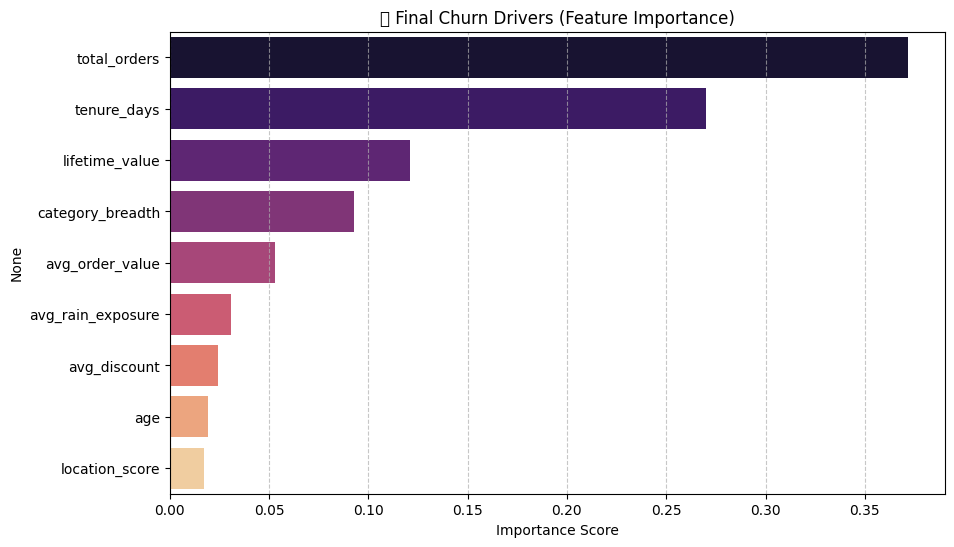

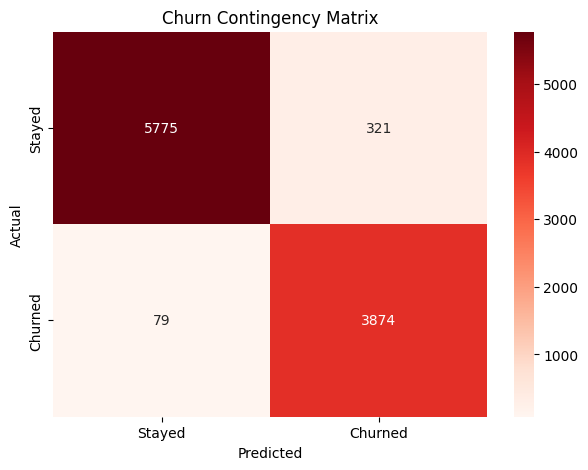

📋 CLASSIFICATION REPORT
------------------------------
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      6096
           1       0.92      0.98      0.95      3953

    accuracy                           0.96     10049
   macro avg       0.95      0.96      0.96     10049
weighted avg       0.96      0.96      0.96     10049

ROC-AUC Score: 0.9825


In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# 1. FINAL FEATURE CLEANING
# We must drop the string 'location' column so the Scaler only sees numbers
if 'location' in X.columns:
    X = X.drop(columns=['location'])

# 2. SYNCED SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. SCALING
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. RE-TRAIN MODEL
# We keep 'balanced' to handle the 60/40 split naturally
model = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
model.fit(X_train_scaled, y_train)

# 5. GENERATE FEATURE IMPORTANCE
importances = model.feature_importances_
feat_imp = pd.Series(importances, index=X.columns).sort_values(ascending=False)

# --- VISUALIZATION 1: FEATURE IMPORTANCE ---
plt.figure(figsize=(10, 6))
sns.barplot(x=feat_imp.values, y=feat_imp.index, palette='magma')
plt.title("🏆 Final Churn Drivers (Feature Importance)")
plt.xlabel("Importance Score")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

# --- VISUALIZATION 2: CONTINGENCY MATRIX ---
y_pred = model.predict(X_test_scaled)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=['Stayed', 'Churned'], 
            yticklabels=['Stayed', 'Churned'])
plt.title("Churn Contingency Matrix")
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# --- FINAL MEASURES REPORT ---
print("📋 CLASSIFICATION REPORT")
print("-" * 30)
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, model.predict_proba(X_test_scaled)[:, 1]):.4f}")